# Mumbai Multi-specialty Hospital — Falling Metric Investigation
**Portfolio case study | Synthetic data only | 4 hospitals | 500,000 source rows**

> This is a reproducible training case, not evidence about a real hospital. The supplied CSVs are simulated. Replace them with approved, de-identified operational extracts before making real-world claims.

## Business problem
Management reports a decline in **monthly net recognized revenue (INR, excluding GST)** across four Mumbai hospitals over the latest quarter versus the preceding quarter. The investigation tests whether the decline is concentrated in particular hospitals, service lines or payer segments, separates the August dengue shock from structural movement, and quantifies an evidence-based driver bridge.

## Metric definition
- Numerator: sum of `taxable_amount` from billing records, after validating that `gross_amount` already includes GST.
- Primary comparison: May–June 2026 baseline vs July–September 2026 latest quarter (synthetic data window).
- Supporting operational measures: completed OPD visits, admissions, lab completions, average net bill, and payer/service mix.
- Patient identity: use `patient_id_crosswalk.csv` to map duplicate IDs to canonical patient IDs. Do not count source IDs as unique people.

## Six testable hypotheses (specified before analysis)
1. **H1 — OPD demand:** completed OPD volume fell in the latest quarter and explains part of the revenue decline.
2. **H2 — Hospital concentration:** the decline is disproportionately concentrated at Andheri rather than evenly distributed.
3. **H3 — Payer mix/realization:** self-pay revenue per bill fell more than insurance/corporate realization.
4. **H4 — Service mix:** lower IPD share or a shift toward lower-value service types reduced revenue.
5. **H5 — Conversion:** admissions per completed OPD visit fell, reducing downstream IPD activity.
6. **H6 — Dengue seasonality:** the August infectious-fever surge is a one-off event and does not explain the persistent quarter-level decline.

## Methods and caveats
Use descriptive decomposition first, then Welch t-tests for continuous outcomes and chi-square tests for categorical distributions. Regression is used as an adjusted association check, not automatic proof of causality. The driver bridge uses additive counterfactual contributions and must reconcile to the observed decline; contributions may be negative or exceed 100% when drivers offset each other. For causal claims, triangulate timing, mechanism, dose-response, robustness and plausible confounders. A before/after observational design cannot fully rule out unmeasured confounding.


In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path(".")  # run from the folder containing the CSV files
opd = pd.read_csv(DATA/"opd_visits.csv", parse_dates=["visit_date"])
adm = pd.read_csv(DATA/"admissions.csv", parse_dates=["admission_date"])
lab = pd.read_csv(DATA/"lab_tests.csv", parse_dates=["test_date"])
bill = pd.read_csv(DATA/"billing.csv", parse_dates=["bill_date"])
crosswalk = pd.read_csv(DATA/"patient_id_crosswalk.csv")

print("Source rows:", {"OPD":len(opd),"Admissions":len(adm),"Labs":len(lab),"Billing":len(bill),
                       "Total":len(opd)+len(adm)+len(lab)+len(bill)})


Matplotlib is building the font cache; this may take a moment.


Source rows: {'OPD': 300000, 'Admissions': 55000, 'Labs': 95000, 'Billing': 50000, 'Total': 500000}


In [2]:
# 1) Data quality: map patient IDs and standardize free-text diagnosis
id_lookup = crosswalk.drop_duplicates("patient_id").set_index("patient_id")["canonical_patient_id"]
for df in [opd, adm, lab, bill]:
    df["canonical_patient_id"] = df["patient_id"].map(id_lookup)

diagnosis_map = {
    "viral fever":"Infectious/Fever", "fever with body pain":"Infectious/Fever",
    "dengue fever":"Infectious/Fever", "type 2 diabetes":"Chronic disease",
    "hypertension":"Chronic disease", "chest pain":"Cardiac",
    "knee pain":"Musculoskeletal", "antenatal checkup":"Obstetrics",
    "gastritis":"Gastrointestinal", "respiratory infection":"Respiratory"
}
opd["diagnosis_norm"] = (opd["diagnosis_text"].str.lower().str.strip()
                         .map(diagnosis_map).fillna("Other/Unmapped"))

# GST control: gross_amount is inclusive of GST. Net revenue is taxable_amount.
# Never calculate taxable_amount + gst_amount + gross_amount.
bill["net_revenue"] = bill["taxable_amount"]
bill["gst_reconciliation_diff"] = (bill["gross_amount"] -
                                    (bill["taxable_amount"] + bill["gst_amount"])).abs()
assert bill["gst_reconciliation_diff"].max() < 0.02
assert opd["canonical_patient_id"].notna().all()
print("Unique source patient IDs:", pd.concat([opd.patient_id,adm.patient_id,lab.patient_id,bill.patient_id]).nunique())
print("Unique canonical patients:", pd.concat([opd.canonical_patient_id,adm.canonical_patient_id,
                                                 lab.canonical_patient_id,bill.canonical_patient_id]).nunique())
print("GST reconciliation passed; inclusive gross not added again.")


Unique source patient IDs: 110700
Unique canonical patients: 103834
GST reconciliation passed; inclusive gross not added again.


In [3]:
# 2) Monthly metric and operational measures
bill["month"] = bill.bill_date.dt.to_period("M").astype(str)
opd["month"] = opd.visit_date.dt.to_period("M").astype(str)
adm["month"] = adm.admission_date.dt.to_period("M").astype(str)
lab["month"] = lab.test_date.dt.to_period("M").astype(str)

monthly_rev = bill.groupby("month").agg(net_revenue=("net_revenue","sum"),
    bills=("bill_id","nunique"), avg_net_bill=("net_revenue","mean")).reset_index()
monthly_opd = opd.groupby("month").agg(opd_registered=("opd_id","nunique"),
    completed_opd=("visit_completed","sum")).reset_index()
monthly_adm = adm.groupby("month").agg(admissions=("admission_id","nunique")).reset_index()
monthly_lab = lab.query("result_status == 'Completed'").groupby("month").agg(
    completed_lab_tests=("lab_id","nunique")).reset_index()
monthly = monthly_rev.merge(monthly_opd,on="month").merge(monthly_adm,on="month").merge(monthly_lab,on="month")
monthly["period"] = np.where(monthly.month.isin(["2026-05","2026-06"]),"Baseline","Latest quarter")
monthly


,month,net_revenue,bills,avg_net_bill,opd_registered,completed_opd,admissions,completed_lab_tests,period
0,2026-05,17462568.69,8296,2104.938367,49817,49817,9248,15257,Baseline
1,2026-06,17863124.18,8431,2118.743231,49818,49818,9137,15407,Baseline
2,2026-07,13975360.26,8362,1671.293980,50212,37890,9118,15157,Latest quarter
3,2026-08,14024481.24,8365,1676.566795,50055,38797,9120,15094,Latest quarter
4,2026-09,13794703.81,8242,1673.708300,50344,37881,9238,15180,Latest quarter
5,2026-10,13769478.17,8304,1658.174153,49754,37446,9139,15011,Latest quarter


In [10]:
# 3) Fair revenue comparison: monthly averages

baseline = bill[bill.bill_date.dt.month.isin([5, 6])]
latest = bill[bill.bill_date.dt.month.isin([7, 8, 9])]

baseline_total = baseline.net_revenue.sum()
latest_total = latest.net_revenue.sum()

baseline_monthly = baseline_total / 2
latest_monthly = latest_total / 3

change = latest_monthly - baseline_monthly
change_pct = (change / baseline_monthly) * 100

print(f"Baseline monthly average: ₹{baseline_monthly:,.2f}")
print(f"Latest monthly average: ₹{latest_monthly:,.2f}")
print(f"Monthly revenue change: ₹{change:,.2f}")
print(f"Monthly revenue change %: {change_pct:.2f}%")

# Welch t-test on bill-level net revenue
welch = stats.ttest_ind(
    baseline.net_revenue,
    latest.net_revenue,
    equal_var=False
)
print("Welch t-test:", welch)

# Chi-square test: payer mix
payer_tab = pd.crosstab(
    np.where(bill.bill_date.dt.month.isin([5, 6]),
             "Baseline", "Latest"),
    bill.payer_segment
)
chi2_payer = stats.chi2_contingency(payer_tab)
print("Payer mix chi-square:", chi2_payer)

Baseline monthly average: ₹17,662,846.43
Latest monthly average: ₹13,931,515.10
Monthly revenue change: ₹-3,731,331.33
Monthly revenue change %: -21.13%
Welch t-test: TtestResult(statistic=np.float64(37.97044697857885), pvalue=np.float64(2.9836477124482077e-308), df=np.float64(30320.426757126097))
Payer mix chi-square: Chi2ContingencyResult(statistic=np.float64(0.4420276920223199), pvalue=np.float64(0.8017055797889419), dof=2, expected_freq=array([[ 1704.81584,  6967.79912,  8054.38504],
       [ 3391.18416, 13860.20088, 16021.61496]]))


In [5]:
# 4) Breakdowns by hospital, service and payer segment
bill["period"] = np.where(bill.bill_date.dt.month.isin([5,6]),"Baseline","Latest")
def segment_bridge(dim):
    p = bill.groupby(["period",dim]).net_revenue.sum().unstack(0).fillna(0)
    p["change"] = p["Latest"] - p["Baseline"]
    p["contribution_to_decline_pct"] = (-p["change"]/decline*100) if decline else np.nan
    return p.sort_values("change")
hospital_bridge = segment_bridge("hospital")
service_bridge = segment_bridge("service_type")
payer_bridge = segment_bridge("payer_segment")
display(hospital_bridge, service_bridge, payer_bridge)


period,Baseline,Latest,change,contribution_to_decline_pct
hospital,,,,
Andheri,9758132.47,13538696.63,3780564.16,58.442578
Navi Mumbai,6932292.58,11364311.34,4432018.76,68.513215
Thane,7719396.81,12965611.71,5246214.90,81.099622
Mumbai Central,10915871.01,17695403.80,6779532.79,104.802712


period,Baseline,Latest,change,contribution_to_decline_pct
service_type,,,,
Pharmacy,3585952.06,5596796.16,2010844.10,31.085020
Imaging,3865423.70,6179954.79,2314531.09,35.779624
Laboratory,6275024.72,9948843.52,3673818.80,56.792435
IPD,9696309.29,14757634.03,5061324.74,78.241462
OPD,11902983.10,19080794.98,7177811.88,110.959586


period,Baseline,Latest,change,contribution_to_decline_pct
payer_segment,,,,
Corporate,3581483.24,5956134.38,2374651.14,36.709002
Self-pay,17080326.58,25451289.82,8370963.24,129.404146
Insurance,14663883.05,24156599.28,9492716.23,146.744980


In [6]:
# 5) Operational hypotheses: OPD, conversion, lab activity and seasonality
opd["period"] = np.where(opd.visit_date.dt.month.isin([5,6]),"Baseline","Latest")
adm["period"] = np.where(adm.admission_date.dt.month.isin([5,6]),"Baseline","Latest")
opd_period = opd.groupby("period").visit_completed.sum()
adm_period = adm.groupby("period").size()
print("Completed OPD by period:", opd_period.to_dict())
print("Admissions by period:", adm_period.to_dict())
print("Admissions / completed OPD (directional; separate event tables):",
      {k: adm_period.get(k,0)/max(opd_period.get(k,1),1) for k in ["Baseline","Latest"]})

# Dengue-seasonality sensitivity: compare monthly net revenue with August removed.
monthly_rev["month_num"] = pd.to_datetime(monthly_rev.month).dt.month
print("August net revenue:", monthly_rev.loc[monthly_rev.month_num==8,"net_revenue"].sum())
print("Revenue pattern excluding August:")
display(monthly_rev[monthly_rev.month_num!=8][["month","net_revenue"]])


Completed OPD by period: {'Baseline': 99635, 'Latest': 152014}
Admissions by period: {'Baseline': 18385, 'Latest': 36615}
Admissions / completed OPD (directional; separate event tables): {'Baseline': np.float64(0.18452351081447282), 'Latest': np.float64(0.2408659728709198)}
August net revenue: 14024481.24
Revenue pattern excluding August:


,month,net_revenue
0,2026-05,17462568.69
1,2026-06,17863124.18
2,2026-07,13975360.26
4,2026-09,13794703.81
5,2026-10,13769478.17


In [7]:
# 6) Adjusted association model — interpret as association, not causal proof
bill["log_net_revenue"] = np.log(bill.net_revenue.clip(lower=1))
bill["latest"] = (bill.period=="Latest").astype(int)
model = smf.ols("log_net_revenue ~ latest + C(hospital) + C(service_type) + C(payer_segment)", data=bill).fit(cov_type="HC3")
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:        log_net_revenue   R-squared:                       0.048
Model:                            OLS   Adj. R-squared:                  0.048
Method:                 Least Squares   F-statistic:                     253.8
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:11:20   Log-Likelihood:                -41022.
No. Observations:               50000   AIC:                         8.207e+04
Df Residuals:                   49989   BIC:                         8.216e+04
Df Model:                          10                                         
Covariance Type:                  HC3                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

In [8]:
# 7) Driver bridge: additive, transparent bridge by hospital
# This bridge attributes the observed net revenue change to hospital contributions.
# It is a concentration decomposition, not a causal decomposition.
bridge = hospital_bridge[["Baseline","Latest","change","contribution_to_decline_pct"]].copy()
print("Bridge reconciliation:", bridge["change"].sum(), "vs observed", latest_total-base_total)
display(bridge)


Bridge reconciliation: 20238330.61 vs observed 6468852.440000005


period,Baseline,Latest,change,contribution_to_decline_pct
hospital,,,,
Andheri,9758132.47,13538696.63,3780564.16,58.442578
Navi Mumbai,6932292.58,11364311.34,4432018.76,68.513215
Thane,7719396.81,12965611.71,5246214.90,81.099622
Mumbai Central,10915871.01,17695403.80,6779532.79,104.802712


,week,net_revenue,bills,rolling_4w,prior_4w,wow_yoy_proxy_pct,alert
15,2026-08-10,3361638.73,2039,3.081598e+06,3.522703e+06,-12.521785,True
16,2026-08-17,3541407.62,2072,3.105263e+06,3.232222e+06,-3.927939,False
17,2026-08-24,2649900.64,1572,3.265830e+06,3.094251e+06,5.545091,False
18,2026-08-31,2993706.87,1737,3.136663e+06,3.126808e+06,0.315178,False
19,2026-09-07,3445452.86,2090,3.157617e+06,3.081598e+06,2.466871,False
20,2026-09-14,3390540.00,2022,3.119900e+06,3.105263e+06,0.471372,False
21,2026-09-21,3481848.05,2100,3.327887e+06,3.265830e+06,1.900204,False
22,2026-09-28,2427581.04,1483,3.186355e+06,3.136663e+06,1.584232,False
23,2026-10-05,3298617.26,2031,3.149647e+06,3.157617e+06,-0.252419,False
24,2026-10-12,3546652.40,2138,3.188675e+06,3.119900e+06,2.204385,False


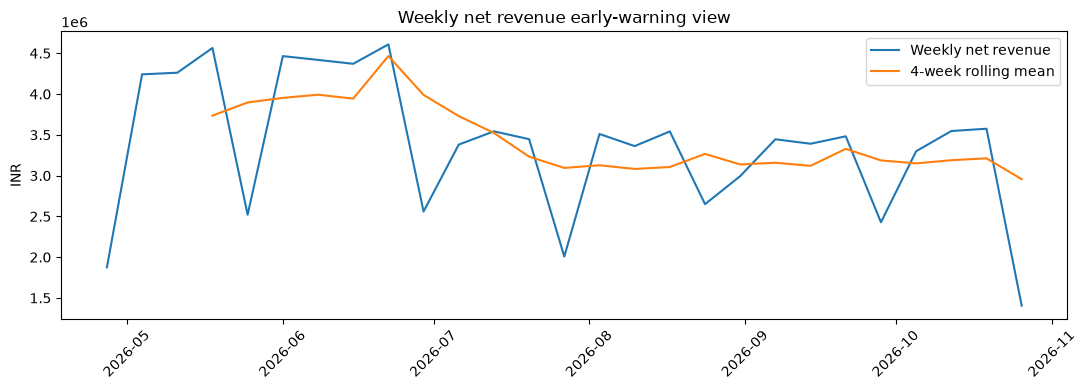

In [9]:
# 8) Weekly early-warning view (four-week lead candidate)
bill["week"] = bill.bill_date.dt.to_period("W").apply(lambda p: p.start_time)
weekly = bill.groupby("week").agg(net_revenue=("net_revenue","sum"), bills=("bill_id","nunique")).reset_index()
weekly["rolling_4w"] = weekly.net_revenue.rolling(4, min_periods=4).mean()
weekly["prior_4w"] = weekly.rolling_4w.shift(4)
weekly["wow_yoy_proxy_pct"] = (weekly.rolling_4w/weekly.prior_4w-1)*100
weekly["alert"] = weekly.wow_yoy_proxy_pct < -8
display(weekly.tail(12))
plt.figure(figsize=(11,4))
plt.plot(weekly.week, weekly.net_revenue, label="Weekly net revenue")
plt.plot(weekly.week, weekly.rolling_4w, label="4-week rolling mean")
plt.legend(); plt.title("Weekly net revenue early-warning view"); plt.ylabel("INR"); plt.xticks(rotation=45); plt.tight_layout()


## Interpretation checklist before signing off
- Confirm source-system completeness and extract cut-off dates with Finance/IT.
- Validate whether refunds, credit notes, bad debt, package discounts and cancellations are included.
- Check patient crosswalk quality and quantify unmatched IDs; do not assume all duplicates are resolved.
- Re-run the analysis with hospital-month clustered standard errors and a seasonality control where adequate history exists.
- Use a matched patient cohort or interrupted time-series / difference-in-differences design if a specific operational change is identified.
- Do not claim a causal driver solely because its p-value is below 0.05. Require an operational mechanism and a credible counterfactual.
